In [2]:
from reasoning_from_scratch.ch03 import render_prompt 

raw_prompt = (
    'Half the value of $3x-9$ is $x+37$. ' 
    "What is thevalue of $x$?"
)
prompt = render_prompt(raw_prompt)
print(prompt)

You are a helpful math assistant.
Answer the question and write the final result on a new line as:
\boxed{ANSWER}

Question:
Half the value of $3x-9$ is $x+37$. What is thevalue of $x$?

Answer:


In [3]:
from reasoning_from_scratch.ch02 import generate_text_basic_stream_cache 

def generate_text_stream_concat_flex(
    model, tokenizer, prompt, device, max_new_tokens, verbose = False, generate_func = None, **generate_kwargs
):
    if generate_func is None:
        generate_func = generate_text_basic_stream_cache 
        
    input_ids = torch.tensor(
        tokenizer.encode(prompt), device = device 
    ).unsqueeze(0)
    
    generated_ids = []
    for token in generate_func(
        model = model,
        token_ids = input_ids,
        max_new_tokens = max_new_tokens,
        eos_token_id = tokenizer.eos_token_id,
        **generate_kwargs,
    ):
        next_token_id = token.squeeze(0)
        generated_ids.append(next_token_id.item())
        
        if verbose:
            print(
                tokenizer.decode(next_token_id.tolist()),
                end = '', 
                flush = True
            )
    return tokenizer.decode(generated_ids)    # this function takes a prompt and returns the model’s full generated response as text.

In [4]:
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device, max_new_tokens = 2048, verbose = True,
    generate_func = generate_text_basic_stream_cache
)
# answering/generating without computation and time, thus wrong answer 

 \boxed{20}

In [5]:
prompt_cot = prompt + '\n\nExplains step by step. '          # usign chain of thought 

respone_cot = generate_text_stream_concat_flex(
    model, tokenizer, prompt_cot, device, 
    max_new_tokens = 2048, verbose = True,
)

1. Start with the given equation: Half the value of $3x-9$ is $x+37$.
2. Write the equation as: $\frac{1}{2}(3x-9) = x+37$.
3. Multiply both sides of the equation by 2 to eliminate the fraction: $3x-9 = 2(x+37)$.
4. Distribute the 2 on the right side of the equation: $3x-9 = 2x+74$.
5. Subtract $2x$ from both sides of the equation: $x-9 = 74$.
6. Add 9 to both sides of the equation: $x = 83$.
7. The value of $x$ is 83.

In [6]:
ex_prompt = 'The capital of Germany is'

response = generate_text_stream_concat_flex(
    model, tokenizer, ex_prompt, device, max_new_tokens = 1, verbose = True 
)

 Berlin

In [7]:
input_token_ids = torch.tensor(
    tokenizer.encode(ex_prompt), device = device
).unsqueeze(0)
print(input_token_ids)

tensor([[ 785, 6722,  315, 9856,  374]])


In [8]:
with torch.inference_mode():
    next_token_logits = model(input_token_ids)[:, -1]       # drops the token's dimension 
print(next_token_logits.shape)

torch.Size([1, 151936])


In [9]:
a = model(input_token_ids)[:, -1]
print(a.shape)
print()
a

torch.Size([1, 151936])



tensor([[ 8.8125, 10.6875,  8.5625,  ..., -2.2969, -2.2969, -2.2969]],
       dtype=torch.bfloat16, grad_fn=<SelectBackward0>)

In [10]:
max_token_id = torch.argmax(next_token_logits)
print(f'token ID: {max_token_id}')
print(f"decoded token: '{tokenizer.decode([max_token_id])}'")

token ID: 19846
decoded token: ' Berlin'


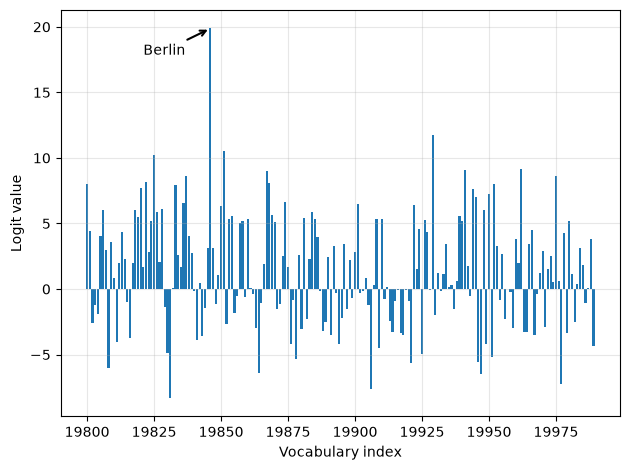

In [11]:
import matplotlib.pyplot as plt 

def plot_scores_bar(
    next_token_logits, start = 19_800, end = 19_990,
    arrow = True, ylabel = 'Logit value' 
):
    x = torch.arange(start, end)
    logits_section = next_token_logits[0, start:end].float().cpu()
    
    plt.bar(x, logits_section)
    plt.xlabel('Vocabulary index')
    plt.ylabel(ylabel)
    
    if arrow:
        max_idx = torch.argmax(logits_section)
        plt.annotate(
            'Berlin',
            xy = (x[max_idx], logits_section[max_idx]),
            xytext = (x[max_idx] - 25, logits_section[max_idx] - 2),
            arrowprops = {
                'facecolor': 'black', 'arrowstyle': '->', 'lw': 1.5
            },
            fontsize = 10
        )
    plt.grid(alpha = 0.3)
    plt.tight_layout()
    plt.show()
plot_scores_bar(next_token_logits)

In [12]:
def scale_logits_by_temperature(logits, temperature):
    if temperature <= 0:
        raise ValueError('temperature must be positive')
    return logits/temperature

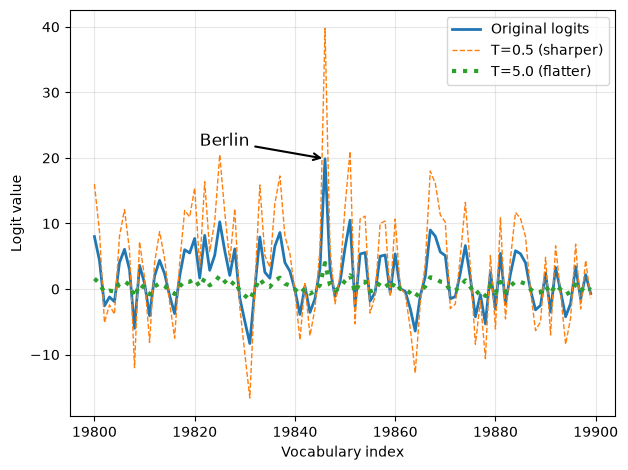

In [13]:
def plot_logits_with_temperature(
    next_token_logits, start=19_800, end=19_900,
    temps=(0.5, 5.0),
):
    x = torch.arange(start, end)
    logits_orig = next_token_logits[0, start:end].float().cpu()

    logits_scaled = [
        scale_logits_by_temperature(logits_orig, T) for T in temps
    ]

    plt.plot(x, logits_orig, label="Original logits", lw=2)
    plt.plot(
        x, logits_scaled[0],
        label=f"T={temps[0]} (sharper)", ls="--", lw=1
    )
    plt.plot(
        x, logits_scaled[1],
        label=f"T={temps[1]} (flatter)", ls=":", lw=3
    )

    # Highlight max logit
    max_idx = torch.argmax(logits_orig)
    plt.annotate(
        "Berlin",
        xy=(x[max_idx], logits_orig[max_idx]),
        xytext=(x[max_idx] - 25, logits_orig[max_idx] + 2),
        arrowprops={"facecolor": "black", "arrowstyle": "->", "lw": 1.5},
        fontsize=12,
    )

    plt.xlabel("Vocabulary index")
    plt.ylabel("Logit value")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_logits_with_temperature(
    next_token_logits,
    temps=(0.5, 5.0)
)

In [14]:
rescaled_logits = scale_logits_by_temperature(next_token_logits, 5.0)

next_token_probas = torch.softmax(           # normalizes the logit values to the range from 0 to 1, 
    rescaled_logits, dim = -1                # such that they sum to 1
)

In [46]:
print('probability sum:', torch.sum(next_token_probas))


probability sum: tensor(1., dtype=torch.bfloat16)


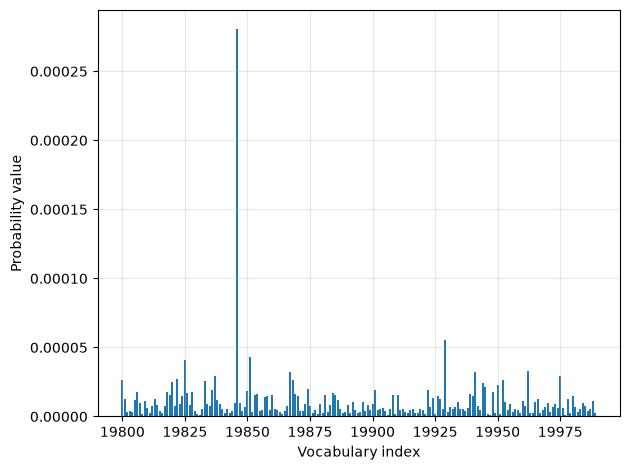

In [16]:
plot_scores_bar(
next_token_probas, arrow=False, ylabel="Probability value"
)

In [17]:
print('token id 19,846 probability:', next_token_probas[:, 19846])

token id 19,846 probability: tensor([0.0003], dtype=torch.bfloat16)


In [18]:
print('highest probability:', max(next_token_probas.squeeze(0)))

highest probability: tensor(0.0003, dtype=torch.bfloat16)


In [19]:
torch.manual_seed(123)
print(
    'sampled token:', torch.multinomial(next_token_probas.cpu(), num_samples = 1)
)

sampled token: tensor([[65094]])


In [20]:
def count_samples(probas, num_samples = 1000, threshold = 1, tokenizer = None):
    samples = torch.multinomial(
        probas.cpu(), num_samples = num_samples, replacement = True 
    )
    counts = torch.bincount(samples.squeeze(0), minlength = 1)
    
    for i, c in enumerate(counts):
        if c > threshold:
            if tokenizer is None:
                print(f'vocab index {i}: {c.item()}x')
            else:
                print(f"'{tokenizer.decode([i])}': {c.item()}x") 
                
# this function prints token IDs or decoded tokens and how often they were sampled

In [21]:
torch.manual_seed(123)

count_samples(next_token_probas)
print('\n\n')
count_samples(next_token_probas, tokenizer = tokenizer)

vocab index 92: 2x
vocab index 690: 2x
vocab index 4009: 2x
vocab index 14921: 2x
vocab index 25010: 2x
vocab index 29388: 2x
vocab index 59148: 2x
vocab index 123853: 2x



' the': 2x
';

': 2x
' really': 2x
' ___': 3x
' broken': 2x
' "&': 2x
' Bon': 2x
' Berlin': 3x
' horses': 2x
' Summit': 2x
' Reload': 2x
' FRE': 2x
'(which': 2x
' München': 2x
' BER': 2x


In [22]:
torch.manual_seed(123)

probas_lowT = torch.softmax(
    scale_logits_by_temperature(next_token_logits, 0.35), dim = -1
)
count_samples(probas_lowT, tokenizer=tokenizer)

' __': 158x
' Berlin': 435x
' ____': 169x
' ______': 209x
' Munich': 3x
' Hamburg': 3x
' _____': 18x


In [23]:
from reasoning_from_scratch.qwen3 import KVCache 

@torch.inference_mode()
def generate_text_temp_stream_cache(
    model, token_ids, max_new_tokens, eos_token_id = None, temperature = 0.):
    
    model.eval()
    cache = KVCache(n_layers = model.cfg['n_layers'])
    model.reset_kv_cache()
    
    out = model(token_ids, cache = cache)[:, -1]
    for _ in range(max_new_tokens):
        
        ###############################
        # NEW
        orig_device = token_ids.device 
        
        if temperature is None or temperature == 0.0:
             next_token = torch.argmax(out, dim = -1, keepdim = True)
        else:
            logits = scale_logits_by_temperature(out, temperature)
            probas = torch.softmax(logits, dim = -1)
            next_token = torch.multinomial(probas.cpu(), num_samples = 1)
            next_token = next_token.to(orig_device)
             
        #################################
        if (eos_token_id is not None and torch.all(next_token == eos_token_id)):
            break 
        
        yield next_token 
        out = model(next_token, cache = cache)[:, -1]

In [24]:
torch.manual_seed(123)

response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device, max_new_tokens = 2048, verbose = True, 
    generate_func = generate_text_temp_stream_cache,
    temperature = 1.1
)

 We begin with the equation \(\frac{1}{2}(3x - 9) = x + 37\).
First, distribute the \(\frac{1}{2}\) on the left-side of the equation to get \(3x - 9 = 2(x + 37)\).
Then simplify the right side of the equation by using the distributive property and combining like terms: \(3x - 9 = 2x + 74\).
Next, subtract \(2x\) from both sides of the equation to get \(x - 9 = 2x + 74\).
Next, subtract \(x\) from both sides of the equation to reduce the number of \(x\) terms on the right side to exactly 1: \(-9 = x + 74\).
Finally, subtract 74 from both sides of the equation to get \(−83 = x\).
The value of \(x\) is \(\boxed{-83}\).

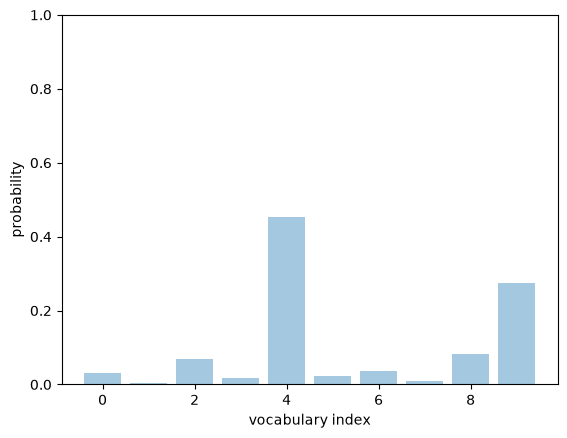

In [25]:
toy_logits = torch.tensor(
    [-0.7, -3.0, 0.1, -1.2, 2.0, -1.0, -0.5, -2.0, 0.3, 1.5]
)

toy_logits_scaled = scale_logits_by_temperature(toy_logits, 1.0)
toy_probas = torch.softmax(toy_logits_scaled, dim = -1)

plt.bar(
    torch.arange(len(toy_probas)), toy_probas,
    alpha = 0.4
)

plt.ylim([0, 1])
plt.xlabel('vocabulary index')
plt.ylabel('probability')
plt.show()

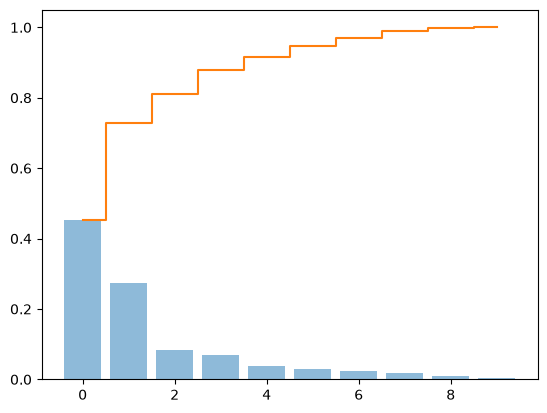

In [26]:
sorted_probas, sorted_idx = torch.sort(toy_probas, descending = True)
cumsum = torch.cumsum(sorted_probas, dim = -1)

plt.bar(torch.arange(len(sorted_probas)), sorted_probas,
        alpha = 0.5
)
plt.step(
    torch.arange(len(cumsum)), cumsum,
    where = 'mid', color = 'C1', label = 'cumulative sum'
)

In [27]:
top_p = 0.8
keep_mask = cumsum <= top_p
n_kept = torch.sum(keep_mask).item()
print('cumulative sum:', cumsum)
print('tokens kept:', n_kept)

cumulative sum: tensor([0.4538, 0.7290, 0.8119, 0.8798, 0.9170, 0.9475, 0.9701, 0.9886, 0.9969,
        1.0000])
tokens kept: 2


In [28]:
keep_mask = (cumsum - sorted_probas) < top_p
n_kept = keep_mask.sum().item()
print('tokens kept:', n_kept)

tokens kept: 3


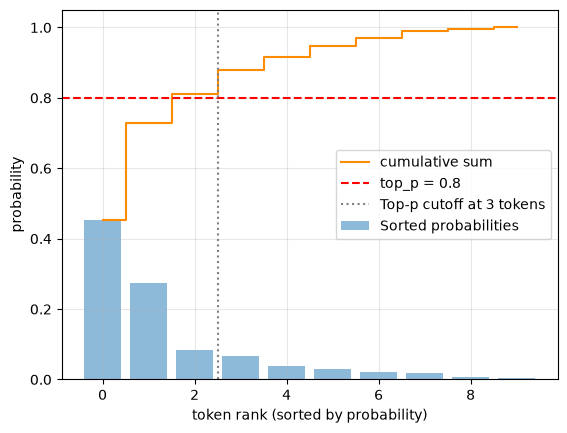

In [29]:
plt.bar(
    torch.arange(len(sorted_probas)), sorted_probas,
    alpha = 0.5, label = 'Sorted probabilities' 
)
plt.step(
    torch.arange(len(cumsum)), cumsum, where = 'mid',
    color = 'darkorange', label = 'cumulative sum' 
)

plt.axhline(
    top_p, color = 'red', linestyle = '--',
    label = f'top_p = {top_p}' 
)
plt.axvline(
    n_kept - 0.5, color = 'gray', linestyle = ':',
    label= f'Top-p cutoff at {n_kept} tokens' 
)

plt.xlabel('token rank (sorted by probability)')
plt.ylabel('probability')
plt.legend()
plt.grid(alpha = 0.3)
plt.ylim(0, 1.05)
plt.show()

In [30]:
kept_sorted = torch.where(keep_mask, sorted_probas, torch.zeros_like(sorted_probas))

filtered = torch.zeros_like(toy_probas).scatter(0, sorted_idx, kept_sorted)
print(filtered)

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.4538, 0.0000, 0.0000, 0.0000, 0.0829,
        0.2752])


In [31]:
denom = torch.sum(filtered).clamp_min(1e-12)
renormalized =  filtered / denom
print(renormalized)

tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.5589, 0.0000, 0.0000, 0.0000, 0.1021,
        0.3390])


In [33]:
def top_p_filter(probas, top_p):
    if top_p is None or top_p >= 1.0:
        return probas 
    
    sorted_probas, sorted_idx = torch.sort(probas, dim = 1, descending = True)
    cumprobas = torch.cumsum(sorted_probas, dim = 1)
    
    prefix = cumprobas - sorted_probas 
    keep = prefix < top_p
    keep[:, 0] = True 
    
    kept_sorted = torch.where(
        keep,
        sorted_probas,
        torch.zeros_like(sorted_probas) 
    )
    
    filtered = torch.zeros_like(probas).scatter(1, sorted_idx, kept_sorted)
    
    denom = torch.sum(filtered, dim = 1, keepdim = True).clamp_min(1e-12)
    return filtered / denom

# It keeps the probabilities where keep=True and replaces the others with 0.

In [34]:
with torch.inference_mode():
    next_token_logits = model(input_token_ids)[:, -1]
print(next_token_logits.shape)

torch.Size([1, 151936])


In [35]:
torch.manual_seed(123)
probas_lowT = torch.softmax(
    scale_logits_by_temperature(next_token_logits, 0.35), dim = -1 
)
count_samples(probas_lowT, threshold = 1, tokenizer = tokenizer)

' __': 158x
' Berlin': 435x
' ____': 169x
' ______': 209x
' Munich': 3x
' Hamburg': 3x
' _____': 18x


In [36]:
torch.manual_seed(123)
probas_lowT = torch.softmax(
    scale_logits_by_temperature(next_token_logits, 0.35), dim = -1   
)
probas_lowT_filtered = top_p_filter(probas_lowT, top_p = 0.8)
count_samples(probas_lowT_filtered, threshold = 1, tokenizer = tokenizer)

' Berlin': 534x
' ____': 217x
' ______': 249x


In [37]:
@torch.inference_mode()

def generate_text_top_p_stream_cache(
    model,
    token_ids,
    max_new_tokens,
    eos_token_id = None,
    temperature = 0.,
    top_p = None 
):
    model.eval()
    cache = KVCache(n_layers = model.cfg['n_layers'])
    model.reset_kv_cache()
    
    out = model(token_ids, cache = cache)[:, -1]
    for _ in range(max_new_tokens):
        
        orig_device = token_ids.device 
        
        if temperature is None or temperature == 0.0:
            next_token = torch.argmax(out, dim = -1, keepdim = True)
        else:
            logits = scale_logits_by_temperature(out, temperature)
            probas = torch.softmax(logits, dim = -1)
            
            probas = top_p_filter(probas, top_p)
            
            next_token = torch.multinomial(probas.cpu(), num_samples = 1)
            next_token = next_token.to(orig_device)
            
        if (eos_token_id is not None and torch.all(next_token == eos_token_id)):
            break 
        
        yield next_token 
        out = model(next_token, cache = cache)[:, -1]

In [42]:
torch.manual_seed(123)
response = generate_text_stream_concat_flex(
    model, tokenizer, prompt, device,
    max_new_tokens = 2048, verbose = True,
    generate_func = generate_text_top_p_stream_cache,
    temperature = 0.5,
    top_p = 0.8,
)

 To solve the equation, we first need to isolate the variable $x$ on one side of the equation. We can do this by subtracting $x$ from both sides of the equation and then dividing both sides by $-2$.

\begin{align*}
\frac{1}{2}(3x-9) &= x+37 \\
\frac{3x-9}{2} &= x+37 \\
\frac{3x}{2} - \frac{9}{2} &= x+37 \\
\frac{3x}{2} &= x + 37 + \frac{9}{2} \\
\frac{3x}{2} &= x + \frac{73}{2} \\
\frac{3x}{2} - x &= \frac{73}{2} \\
\frac{x}{2} &= \frac{73}{2} \\
x &= 73
\end{align*}

Therefore, the value of $x$ is $\boxed{73}$.

In [ ]:
from reasoning_from_scratch.ch03 import extract_final_candidate
from collections import Counter

def self_consistency_vote(
    model, tokenizer, prompt, device,
    num_samples = 10, temperature = 0.8, top_p = 0.9, max_new_tokens = 2048,
    show_progress = True, show_long_answer = False, seed = None, 
):
    full_answers, short_answers = [], []
    
    for i in range(num_samples):
        if seed is not None:
            torch.manual-seed(seed + i + 1)
            
        answer = generate_text_stream_concat_flex(
            model = model, tokenizer = tokenizer, prompt = prompt, device = device,
            max_new_tokens = max_new_tokens, verbose = show_long_answer, 
            generate_func = generate_text_top_p_stream_cache,
            temperature = temperature, top_p = top_p,
        )

In [50]:
a = torch.tensor([2., 4., 8., 5., 7.])
a = torch.softmax(a, dim=0)

print(a)


tensor([0.0017, 0.0127, 0.6952, 0.0346, 0.2557])
